In [2]:
print("hello")

hello


In [3]:
import pandas as pd 
import numpy as np 

In [4]:
df = pd.read_csv(
    r"C:\Users\admin\Desktop\project 2\ONINE_FOOD_DELIVERY_ANALYSIS.csv"
)

In [5]:
df.shape

(100000, 25)

In [6]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


In [7]:
column_list = df.columns.tolist()
column_list

['Order_ID',
 'Customer_ID',
 'Customer_Age',
 'Customer_Gender',
 'City',
 'Area',
 'Restaurant_ID',
 'Restaurant_Name',
 'Cuisine_Type',
 'Order_Date',
 'Order_Time',
 'Delivery_Time_Min',
 'Distance_km',
 'Order_Value',
 'Discount_Applied',
 'Final_Amount',
 'Payment_Mode',
 'Order_Status',
 'Cancellation_Reason',
 'Delivery_Partner_ID',
 'Delivery_Rating',
 'Restaurant_Rating',
 'Order_Day',
 'Peak_Hour',
 'Profit_Margin']

In [8]:
categorical_column = df.select_dtypes(include=["object", "str"]).columns.tolist()
print(categorical_column)

['Order_ID', 'Customer_ID', 'Customer_Gender', 'City', 'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Order_Date', 'Order_Time', 'Payment_Mode', 'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID', 'Order_Day', 'Peak_Hour']


In [9]:
len(column_list)

25

In [10]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount         44303 no

In [11]:
misssing_count = df.isnull().sum()
misssing_count


Order_ID                   0
Customer_ID                0
Customer_Age           50093
Customer_Gender        24856
City                   16726
Area                   16685
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type           16885
Order_Date              1014
Order_Time              1998
Delivery_Time_Min      33359
Distance_km            33470
Order_Value            33327
Discount_Applied       16715
Final_Amount           55697
Payment_Mode           19911
Order_Status               0
Cancellation_Reason    90969
Delivery_Partner_ID        0
Delivery_Rating        16523
Restaurant_Rating          0
Order_Day                  0
Peak_Hour              32962
Profit_Margin              0
dtype: int64

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

Order_ID                0.000
Customer_ID             0.000
Customer_Age           50.093
Customer_Gender        24.856
City                   16.726
Area                   16.685
Restaurant_ID           0.000
Restaurant_Name         0.000
Cuisine_Type           16.885
Order_Date              1.014
Order_Time              1.998
Delivery_Time_Min      33.359
Distance_km            33.470
Order_Value            33.327
Discount_Applied       16.715
Final_Amount           55.697
Payment_Mode           19.911
Order_Status            0.000
Cancellation_Reason    90.969
Delivery_Partner_ID     0.000
Delivery_Rating        16.523
Restaurant_Rating       0.000
Order_Day               0.000
Peak_Hour              32.962
Profit_Margin           0.000
dtype: float64

In [13]:
df["Order_Status"].value_counts()

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64

In [14]:
pd.crosstab(
    df["Order_Status"],
    df["Cancellation_Reason"].isnull()
)

Cancellation_Reason,False,True
Order_Status,,
Cancelled,9031,6005
Delivered,0,84964


In [15]:
df["Order_Status"].value_counts(normalize = True) * 100

Order_Status
Delivered    84.964
Cancelled    15.036
Name: proportion, dtype: float64

In [16]:
df["Cancellation_Reason"].value_counts(dropna = False) * 100

Cancellation_Reason
NaN                   9096900
Late Delivery          305900
Customer Cancelled     299300
Restaurant Issue       297900
Name: count, dtype: int64

In [17]:

cancelled_reason_missing = df[
    (df["Order_Status"] == "Cancelled") &
    (df["Cancellation_Reason"].isnull())
]

cancelled_reason_missing.shape


(6005, 25)

In [18]:
cancelled_reason_missing.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
31,ORD000032,CUST5261,NaN,Female,Delhi,Central,RES403,Restaurant_270,Italian,12/4/2024,...,NaN,Wallet,Cancelled,NaN,DP441,NaN,3.2,Weekday,NaN,0.12
38,ORD000039,CUST9613,NaN,Other,NaN,East,RES110,Restaurant_500,Mexican,5/6/2024,...,622.0,COD,Cancelled,NaN,DP108,2.0,5.5,Weekday,False,0.38
49,ORD000050,CUST3667,NaN,NaN,Bangalore,NaN,RES158,Restaurant_103,Arabian,4/13/2024,...,NaN,COD,Cancelled,NaN,DP539,1.0,3.4,Weekend,NaN,-0.05
60,ORD000061,CUST4574,27.0,Female,Chennai,NaN,RES425,Restaurant_188,Italian,5/9/2024,...,3380.0,Wallet,Cancelled,NaN,DP537,5.0,5.3,Weekday,NaN,0.20
81,ORD000082,CUST4124,43.0,Other,Delhi,Central,RES986,Restaurant_293,NaN,6/19/2024,...,NaN,NaN,Cancelled,NaN,DP734,5.0,5.4,Weekday,True,0.08


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df["Order_ID"].duplicated().sum()

np.int64(0)

In [21]:
for column in column_list:
    print(f"Column: {column}")
    print(f"Unique values : {df[column].nunique()}")
    print(f"Missing values: {df[column].isnull().sum()}")
    print("*" * 40)

Column: Order_ID
Unique values : 100000
Missing values: 0
****************************************
Column: Customer_ID
Unique values : 8999
Missing values: 0
****************************************
Column: Customer_Age
Unique values : 43
Missing values: 50093
****************************************
Column: Customer_Gender
Unique values : 3
Missing values: 24856
****************************************
Column: City
Unique values : 5
Missing values: 16726
****************************************
Column: Area
Unique values : 5
Missing values: 16685
****************************************
Column: Restaurant_ID
Unique values : 900
Missing values: 0
****************************************
Column: Restaurant_Name
Unique values : 500
Missing values: 0
****************************************
Column: Cuisine_Type
Unique values : 5
Missing values: 16885
****************************************
Column: Order_Date
Unique values : 365
Missing values: 1014
***************************************

In [22]:
for column in column_list:
    if df[column].nunique() <= 20:
        print(f"\nColumn: {column}")
        print(df[column].value_counts(dropna=False))
        print("*"*50)


Column: Customer_Gender
Customer_Gender
Other     25135
Female    25031
Male      24978
NaN       24856
Name: count, dtype: int64
**************************************************

Column: City
City
Hyderabad    16884
Bangalore    16732
NaN          16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64
**************************************************

Column: Area
Area
South      16725
NaN        16685
North      16675
West       16653
East       16643
Central    16619
Name: count, dtype: int64
**************************************************

Column: Cuisine_Type
Cuisine_Type
NaN        16885
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64
**************************************************

Column: Order_Time
Order_Time
0:00    98002
NaN      1998
Name: count, dtype: int64
**************************************************

Column: Discount_Applied
Discount_Applied
100.0    16776
Na

In [23]:
df["Order_Time"].sample(10)

228      0:00
80365    0:00
33773    0:00
57038    0:00
64165    0:00
80392    0:00
44111    0:00
55723    0:00
52010    0:00
12447    0:00
Name: Order_Time, dtype: str

In [24]:
df["Order_Time"].value_counts(dropna=False).head(10)

Order_Time
0:00    98002
NaN      1998
Name: count, dtype: int64

In [25]:
df["Order_Time"].dtype

<StringDtype(na_value=nan)>

In [26]:
df["Order_Date"].nunique(dropna=True)

365

In [27]:
df["Order_Date"].isna().sum()

np.int64(1014)

In [28]:
df["Order_Date"].min(), df["Order_Date"].max()

('1/1/2024', '9/9/2024')

In [29]:
df["Order_Date"].dropna().sort_values().head()

117     1/1/2024
788     1/1/2024
1607    1/1/2024
1679    1/1/2024
1872    1/1/2024
Name: Order_Date, dtype: str

In [30]:
df["Order_Date"].dropna().sort_values().tail()

98367    9/9/2024
98594    9/9/2024
98854    9/9/2024
99821    9/9/2024
99889    9/9/2024
Name: Order_Date, dtype: str

In [31]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%m/%d/%Y")
df["Order_Date"].dtype

dtype('<M8[us]')

In [32]:
df["Order_Time"].dropna().unique()

<ArrowStringArray>
['0:00']
Length: 1, dtype: str

In [33]:
df["Customer_Age"].describe()

count    49907.000000
mean        38.976516
std         12.372157
min         18.000000
25%         28.000000
50%         39.000000
75%         50.000000
max         60.000000
Name: Customer_Age, dtype: float64

In [34]:
df.groupby("Customer_Gender")["Customer_Age"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Customer_Gender,,,,,
Female,12518,39.060553,39.0,18.0,60.0
Male,12470,38.891981,39.0,18.0,60.0
Other,12577,38.946251,39.0,18.0,60.0


In [35]:
df.groupby("City")["Customer_Age"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
City,,,,,
Bangalore,8380,38.982578,39.0,18.0,60.0
Chennai,8239,38.932516,39.0,18.0,60.0
Delhi,8361,38.942351,39.0,18.0,60.0
Hyderabad,8468,39.045938,39.0,18.0,60.0
Mumbai,8144,38.838409,39.0,18.0,60.0


In [36]:
df.groupby("Order_Status")["Customer_Age"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Order_Status,,,,,
Cancelled,7471,39.072279,39.0,18.0,60.0
Delivered,42436,38.959657,39.0,18.0,60.0


In [37]:
df["Customer_Age"] = df["Customer_Age"].fillna(39)
df["Customer_Age"].isna().sum()

np.int64(0)

In [38]:
df["Customer_Gender"].isna().sum()


np.int64(24856)

In [39]:
df["Customer_Gender"].value_counts()

Customer_Gender
Other     25135
Female    25031
Male      24978
Name: count, dtype: int64

In [44]:
df["Peak_Hour"] = df["Peak_Hour"].fillna(False)

In [45]:
df["Peak_Hour_Indicator"] = df["Peak_Hour"].astype(int)

In [46]:
print(df["Peak_Hour"].isna().sum())
print(df["Peak_Hour_Indicator"].value_counts())

0
Peak_Hour_Indicator
0    66547
1    33453
Name: count, dtype: int64


## feature 1

In [41]:
df["Order_Day_Type"] = df["Order_Day"]
df["Order_Day_Type"].value_counts(dropna=False)

Order_Day_Type
Weekday    71370
Weekend    28630
Name: count, dtype: int64

## feature 2 

## encoder


In [50]:
id_columns = [
    "Order_ID",
    "Customer_ID",
    "Restaurant_ID",
    "Delivery_Partner_ID"
]
categorical_columns = [
    "Customer_Gender",
    "City",
    "Area",
    "Restaurant_Name",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Cancellation_Reason",
    "Order_Day",
    "Order_Day_Type"
]
numerical_columns = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Final_Amount",
    "Delivery_Rating",
    "Restaurant_Rating",
    "Profit_Margin"
]
date_columns = [
    "Order_Date"
]
time_columns = [
    "Order_Time"
]
boolean_columns = [
    "Peak_Hour"
]
engineered_columns = [
    "Peak_Hour_Indicator"
]

In [51]:
all_grouped_columns = (
    id_columns +
    categorical_columns +
    numerical_columns +
    date_columns +
    time_columns +
    boolean_columns +
    engineered_columns
)

print("Dataset columns:", len(df.columns))
print("Grouped columns:", len(all_grouped_columns))
print("Missing from groups:", set(df.columns) - set(all_grouped_columns))

Dataset columns: 27
Grouped columns: 27
Missing from groups: set()


In [52]:
df_ml = df.copy()

## feature 3 

In [53]:
df["Profit_Margin_Pct"] = df["Profit_Margin"] * 100
df["Profit_Margin_Pct"].head()

0    13.0
1    48.0
2     8.0
3     4.0
4    12.0
Name: Profit_Margin_Pct, dtype: float64

## feature 4 

In [54]:
df["Delivery_Time_Min"].describe()

count    66641.000000
mean       127.475923
std         90.805839
min         20.000000
25%         45.000000
50%        120.000000
75%        210.000000
max        300.000000
Name: Delivery_Time_Min, dtype: float64

In [56]:
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].fillna(120)
print(df["Delivery_Time_Min"].isna().sum())

0


In [57]:
df["Delivery_Time_Min"].describe()

count    100000.000000
mean        124.982030
std          74.211956
min          20.000000
25%          58.000000
50%         120.000000
75%         165.000000
max         300.000000
Name: Delivery_Time_Min, dtype: float64

In [58]:
def delivery_category(time):
    if time <= 60:
        return "Fast"
    elif time <= 120:
        return "Moderate"
    elif time <= 180:
        return "Slow"
    else:
        return "Very Slow"

In [59]:

df["Delivery_Performance"] = df["Delivery_Time_Min"].apply(delivery_category)
df["Delivery_Performance"].value_counts()


Delivery_Performance
Moderate     40141
Fast         26613
Very Slow    22066
Slow         11180
Name: count, dtype: int64

## feature 5 

In [61]:
def age_group(age):
    if age <= 25:
        return "Young Adult"
    elif age <= 35:
        return "Adult"
    elif age <= 50:
        return "Middle Age"
    else:
        return "Senior"

In [62]:
df["Customer_Age_Group"] = df["Customer_Age"].apply(age_group)
df["Customer_Age_Group"].value_counts()

Customer_Age_Group
Middle Age     67609
Adult          11653
Senior         11492
Young Adult     9246
Name: count, dtype: int64

## feature final check

In [63]:
feature_columns = [
    "Order_Day_Type",
    "Peak_Hour_Indicator",
    "Profit_Margin_Pct",
    "Delivery_Performance",
    "Customer_Age_Group"
]

for column in feature_columns:
    print(f"{column}: {df[column].isna().sum()} missing")

Order_Day_Type: 0 missing
Peak_Hour_Indicator: 0 missing
Profit_Margin_Pct: 0 missing
Delivery_Performance: 0 missing
Customer_Age_Group: 0 missing


## EDA

In [64]:
df["Order_Value"].describe()

count    66673.000000
mean      2081.830126
std       1553.628891
min        150.000000
25%        673.000000
50%       1197.000000
75%       3494.000000
max       5000.000000
Name: Order_Value, dtype: float64

In [66]:
df["Order_Value"] = df["Order_Value"].fillna(1197)

In [67]:
print("Missing:", df["Order_Value"].isna().sum())
print("Count:", df["Order_Value"].count())

Missing: 0
Count: 100000


In [68]:
df["Order_Value"].describe()

count    100000.00000
mean       1786.94279
std        1335.39821
min         150.00000
25%         935.00000
50%        1197.00000
75%        2743.00000
max        5000.00000
Name: Order_Value, dtype: float64

In [71]:
pip install matplotlib 

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.3 MB 6.1 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.3 MB 6.7 MB/s eta 0:00:01
   ------------------- -------------------- 4.5/9.3 MB 7.2 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 7.7 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 7.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------- -------------- 1.6/2.5 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 7.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## EDA 1: Order Value Distribution

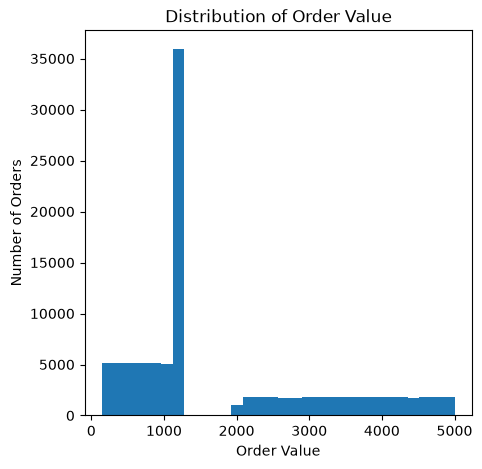

In [73]:
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
plt.hist(df["Order_Value"], bins=30)
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.title("Distribution of Order Value")
plt.show()

## EDA 2 — Delivery Time Distribution

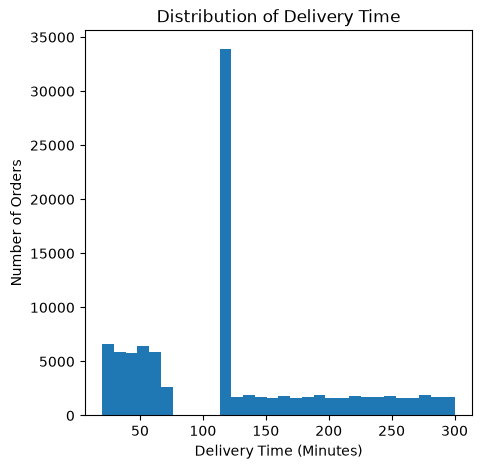

In [74]:
plt.figure(figsize=(5 , 5))
plt.hist(df["Delivery_Time_Min"], bins=30)
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Delivery Time")
plt.show()

In [ ]:
city_orders = df["City"].value_counts()
print(city_orders)

City
Hyderabad    16884
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


In [76]:
print("Missing City:", df["City"].isna().sum())
print("Total rows:", len(df))

Missing City: 16726
Total rows: 100000


In [78]:
df["City"] = df["City"].fillna("Unknown")
print("Missing City:", df["City"].isna().sum())
print(df["City"].value_counts())

Missing City: 0
City
Hyderabad    16884
Bangalore    16732
Unknown      16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


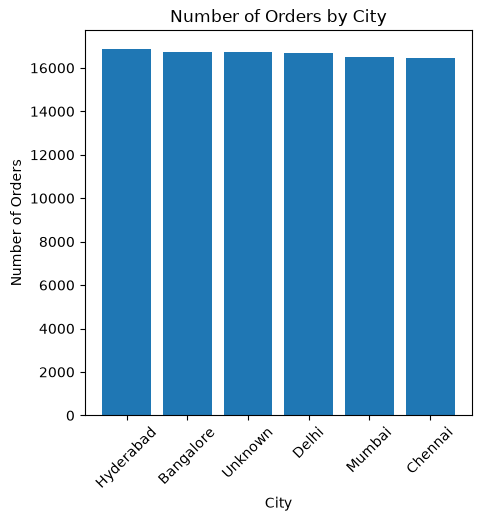

In [81]:
city_orders = df["City"].value_counts()
plt.figure(figsize=(5, 5))
plt.bar(city_orders.index, city_orders.values)
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.title("Number of Orders by City")
plt.xticks(rotation=45)
plt.show()

## EDA 4 — Cuisine Analysis

In [82]:
df["Cuisine_Type"].value_counts()

Cuisine_Type
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64

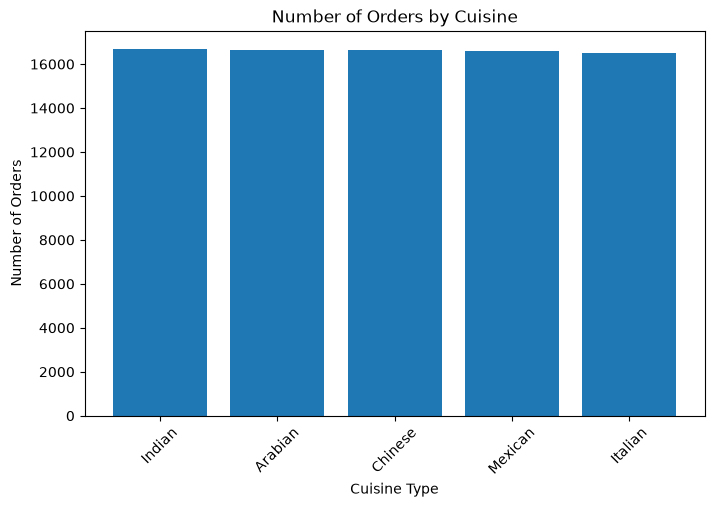

In [84]:
cuisine_orders = df["Cuisine_Type"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(cuisine_orders.index, cuisine_orders.values)
plt.xlabel("Cuisine Type")
plt.ylabel("Number of Orders")
plt.title("Number of Orders by Cuisine")
plt.xticks(rotation=45)
plt.show()

In [85]:
cuisine_revenue = df.groupby("Cuisine_Type")["Final_Amount"].sum().sort_values(ascending=False)
print(cuisine_revenue)

Cuisine_Type
Indian     14782999.0
Mexican    14590977.0
Chinese    14407226.0
Arabian    14311203.0
Italian    13990835.0
Name: Final_Amount, dtype: float64


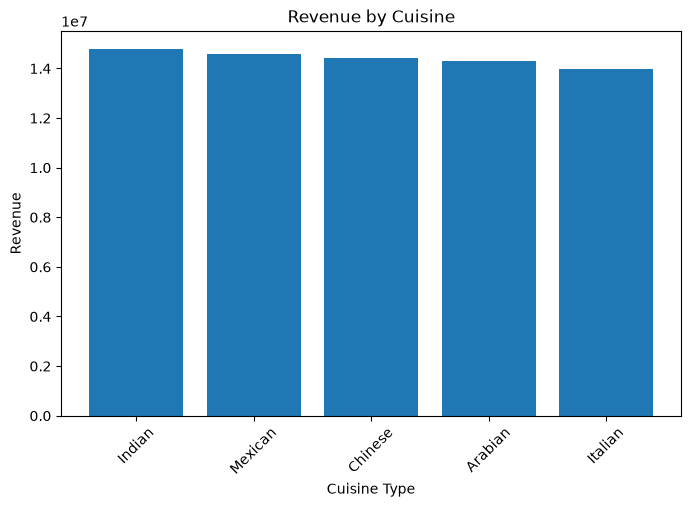

In [86]:
cuisine_revenue = df.groupby("Cuisine_Type")["Final_Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(cuisine_revenue.index, cuisine_revenue.values)
plt.xlabel("Cuisine Type")
plt.ylabel("Revenue")
plt.title("Revenue by Cuisine")
plt.xticks(rotation=45)
plt.show()

## EDA 5 — Weekday vs Weekend

In [87]:
day_orders = df["Order_Day_Type"].value_counts()
print(day_orders)

Order_Day_Type
Weekday    71370
Weekend    28630
Name: count, dtype: int64


In [88]:
day_order_value = df.groupby("Order_Day_Type")["Order_Value"].mean()
print(day_order_value)

Order_Day_Type
Weekday    1789.416968
Weekend    1780.775061
Name: Order_Value, dtype: float64


In [89]:
day_orders = df["Order_Day_Type"].value_counts()
print(day_orders)

Order_Day_Type
Weekday    71370
Weekend    28630
Name: count, dtype: int64


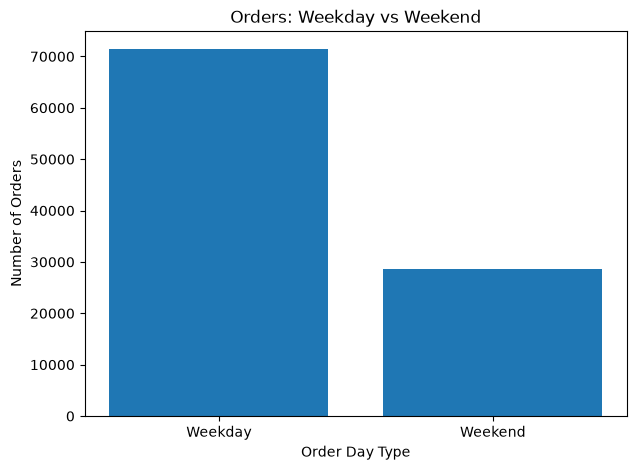

In [90]:
day_orders = df["Order_Day_Type"].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(day_orders.index, day_orders.values)
plt.xlabel("Order Day Type")
plt.ylabel("Number of Orders")
plt.title("Orders: Weekday vs Weekend")
plt.show()

In [91]:
distance_delivery_corr = df[
    ["Distance_km", "Delivery_Time_Min"]
].corr()
print(distance_delivery_corr)


                   Distance_km  Delivery_Time_Min
Distance_km           1.000000           0.002497
Delivery_Time_Min     0.002497           1.000000


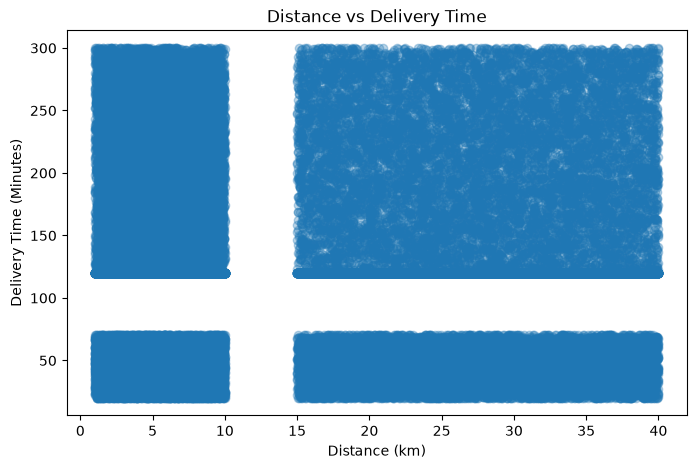

In [92]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Distance_km"],
    df["Delivery_Time_Min"],
    alpha=0.3
)
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")
plt.title("Distance vs Delivery Time")
plt.show()

## Cancellation Analysis

In [93]:
cancellation_rate = (
    df["Order_Status"].eq("Cancelled").mean() * 100
)
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

Cancellation Rate: 15.04%


In [94]:
cancellation_reasons = df.loc[
    df["Order_Status"] == "Cancelled",
    "Cancellation_Reason"
].value_counts()
print(cancellation_reasons)

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


In [95]:
cancelled = df[df["Order_Status"] == "Cancelled"]
print("Total cancelled:", len(cancelled))
print("Missing reason:", cancelled["Cancellation_Reason"].isna().sum())
print("\nReasons:")
print(cancelled["Cancellation_Reason"].value_counts(dropna=False))

Total cancelled: 15036
Missing reason: 6005

Reasons:
Cancellation_Reason
NaN                   6005
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


In [97]:
df.loc[
    (df["Order_Status"] == "Cancelled") &
    (df["Cancellation_Reason"].isna()),
    "Cancellation_Reason"
] = "Unknown"
df.loc[
    (df["Order_Status"] == "Delivered") &
    (df["Cancellation_Reason"].isna()),
    "Cancellation_Reason"
] = "Not Applicable"

In [98]:
print(
    df["Cancellation_Reason"].value_counts()
)

Cancellation_Reason
Not Applicable        84964
Unknown                6005
Late Delivery          3059
Customer Cancelled     2993
Restaurant Issue       2979
Name: count, dtype: int64


## Cancellation Reas000ons00

In [99]:
cancellation_reasons = df.loc[
    df["Order_Status"] == "Cancelled",
    "Cancellation_Reason"
].value_counts()

print(cancellation_reasons)

Cancellation_Reason
Unknown               6005
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


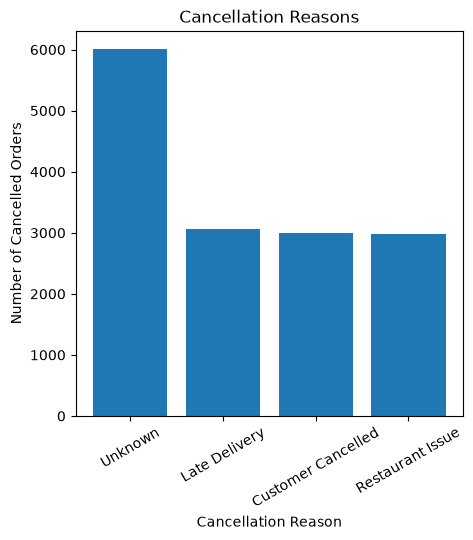

In [100]:
plt.figure(figsize=(5, 5))
plt.bar(cancellation_reasons.index, cancellation_reasons.values)
plt.xlabel("Cancellation Reason")
plt.ylabel("Number of Cancelled Orders")
plt.title("Cancellation Reasons")
plt.xticks(rotation=30)
plt.show()

In [101]:
correlation = df[numerical_columns].corr()
print(correlation.round(2))

                   Customer_Age  Delivery_Time_Min  Distance_km  Order_Value  \
Customer_Age               1.00              -0.01         -0.0         -0.0   
Delivery_Time_Min         -0.01               1.00          0.0          0.0   
Distance_km               -0.00               0.00          1.0          0.0   
Order_Value               -0.00               0.00          0.0          1.0   
Discount_Applied           0.00              -0.00          0.0          0.0   
Final_Amount              -0.00              -0.00         -0.0          1.0   
Delivery_Rating           -0.00               0.00          0.0          0.0   
Restaurant_Rating          0.00               0.00          0.0         -0.0   
Profit_Margin              0.00              -0.00          0.0         -0.0   

                   Discount_Applied  Final_Amount  Delivery_Rating  \
Customer_Age                   0.00         -0.00             -0.0   
Delivery_Time_Min             -0.00         -0.00          

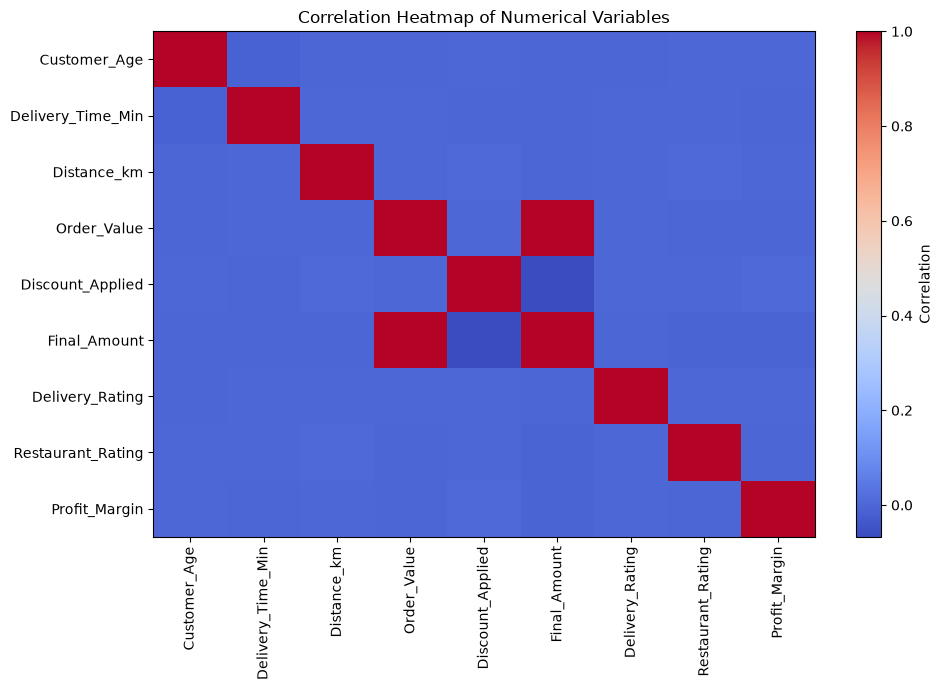

In [102]:
plt.figure(figsize=(10, 7))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

## Monthly Revenue

In [103]:
monthly_revenue = (
    df.dropna(subset=["Order_Date"])
      .groupby(df["Order_Date"].dropna().dt.to_period("M"))["Final_Amount"]
      .sum()
)
print(monthly_revenue)

Order_Date
2024-01    7331096.0
2024-02    6747628.0
2024-03    7047260.0
2024-04    7067149.0
2024-05    7326223.0
2024-06    7251141.0
2024-07    7615597.0
2024-08    7219873.0
2024-09    7261216.0
2024-10    7099918.0
2024-11    7134512.0
2024-12    6910831.0
Freq: M, Name: Final_Amount, dtype: float64


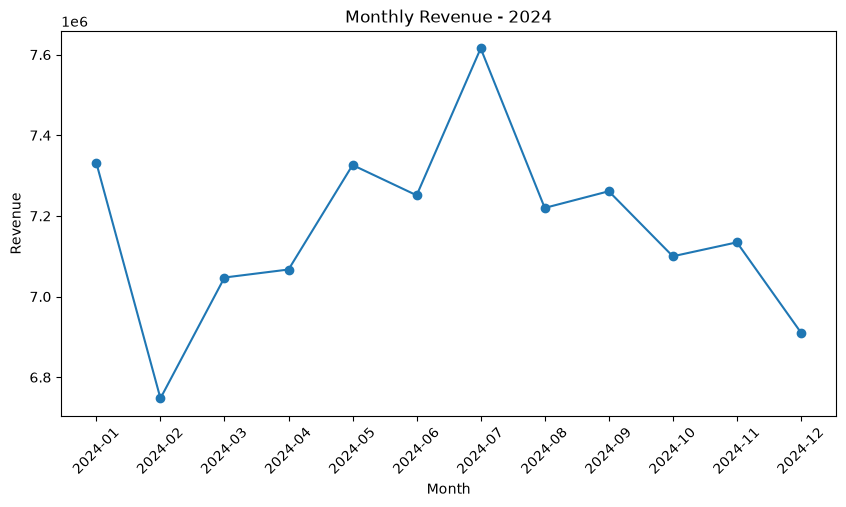

In [104]:
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue - 2024")
plt.xticks(rotation=45)
plt.show()

## Discount vs Profit

In [105]:
discount_profit = (
    df.groupby("Discount_Applied")["Profit_Margin_Pct"]
      .mean()
      .sort_index()
)
print(discount_profit)

Discount_Applied
0.0      15.065465
20.0     14.946647
50.0     14.852906
100.0    15.132570
300.0    15.267771
Name: Profit_Margin_Pct, dtype: float64


## Discount vs Profit Margin

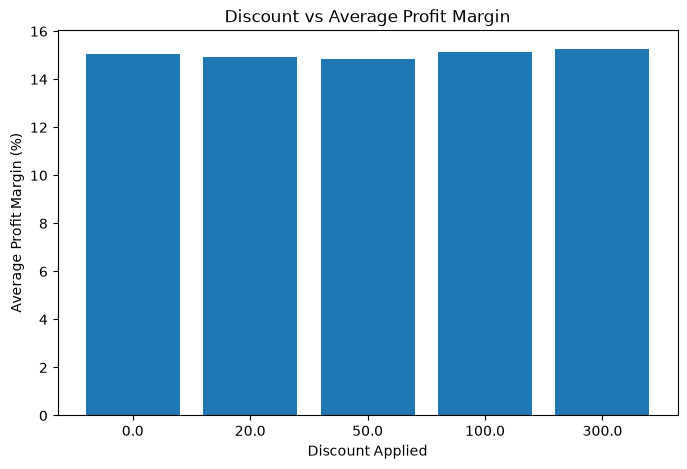

In [106]:
discount_profit = (
    df.groupby("Discount_Applied")["Profit_Margin_Pct"]
      .mean()
      .sort_index()
)
plt.figure(figsize=(8, 5))
plt.bar(
    discount_profit.index.astype(str),
    discount_profit.values
)
plt.xlabel("Discount Applied")
plt.ylabel("Average Profit Margin (%)")
plt.title("Discount vs Average Profit Margin")
plt.show()

## Delivery Time by City

In [107]:
city_delivery = (
    df.groupby("City")["Delivery_Time_Min"]
      .mean()
      .sort_values(ascending=False)
)
print(city_delivery)

City
Mumbai       125.937246
Unknown      125.110307
Hyderabad    125.031805
Delhi        124.896376
Chennai      124.549423
Bangalore    124.373297
Name: Delivery_Time_Min, dtype: float64


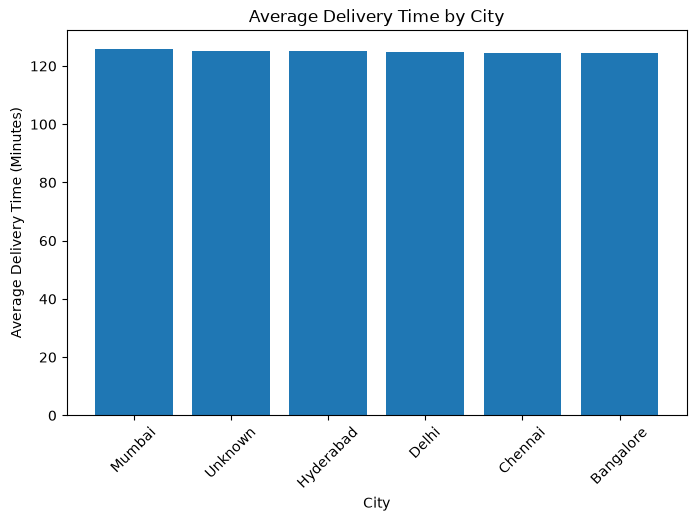

In [108]:
city_delivery = (
    df.groupby("City")["Delivery_Time_Min"]
      .mean()
      .sort_values(ascending=False)
)
plt.figure(figsize=(8, 5))
plt.bar(city_delivery.index, city_delivery.values)
plt.xlabel("City")
plt.ylabel("Average Delivery Time (Minutes)")
plt.title("Average Delivery Time by City")
plt.xticks(rotation=45)
plt.show()

In [109]:
rating_delivery = (
    df.groupby("Delivery_Rating")["Delivery_Time_Min"]
      .mean()
)
print(rating_delivery)

Delivery_Rating
1.0    124.969259
2.0    124.912524
3.0    124.478913
4.0    125.654309
5.0    125.416818
Name: Delivery_Time_Min, dtype: float64


## Delivery Rating vs Delivery Time

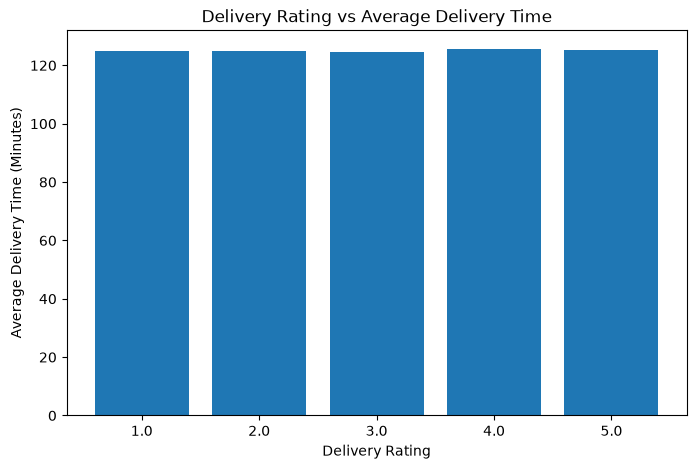

In [111]:
rating_delivery = (
    df.groupby("Delivery_Rating")["Delivery_Time_Min"]
      .mean()
)
plt.figure(figsize=(8, 5))
plt.bar(
    rating_delivery.index.astype(str),
    rating_delivery.values
)
plt.xlabel("Delivery Rating")
plt.ylabel("Average Delivery Time (Minutes)")
plt.title("Delivery Rating vs Average Delivery Time")
plt.show()

## Peak-Hour Demand

In [112]:
peak_orders = df["Peak_Hour"].value_counts()
print(peak_orders)

Peak_Hour
False    66547
True     33453
Name: count, dtype: int64


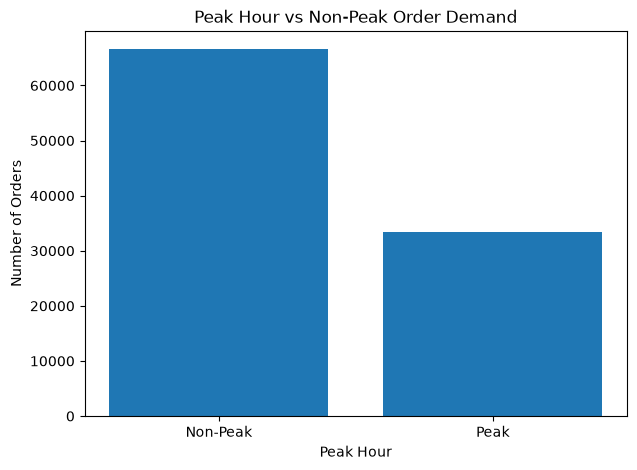

In [113]:
peak_orders = df["Peak_Hour"].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(
    ["Non-Peak", "Peak"],
    [peak_orders[False], peak_orders[True]]
)
plt.xlabel("Peak Hour")
plt.ylabel("Number of Orders")
plt.title("Peak Hour vs Non-Peak Order Demand")
plt.show()

## Payment Mode Analysis

In [114]:
payment_orders = df["Payment_Mode"].value_counts()
print(payment_orders)

Payment_Mode
Card      20094
Wallet    20086
COD       19977
UPI       19932
Name: count, dtype: int64


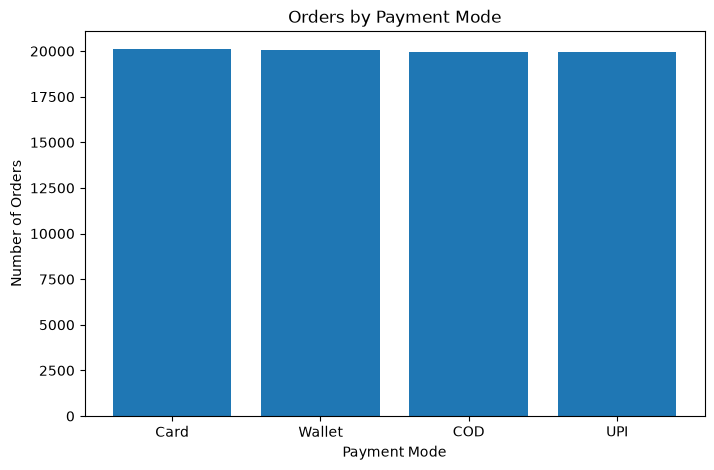

In [115]:
payment_orders = df["Payment_Mode"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(payment_orders.index, payment_orders.values)
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.title("Orders by Payment Mode")
plt.show()

## Restaurant Performance

In [116]:
restaurant_revenue = (
    df.groupby("Restaurant_Name")["Final_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
print(restaurant_revenue)

Restaurant_Name
Restaurant_412    241883.0
Restaurant_221    241773.0
Restaurant_291    240072.0
Restaurant_312    236474.0
Restaurant_418    232203.0
Restaurant_438    228186.0
Restaurant_93     226168.0
Restaurant_191    225787.0
Restaurant_90     220195.0
Restaurant_86     218381.0
Name: Final_Amount, dtype: float64


In [117]:
restaurant_cancellation = (
    df.groupby("Restaurant_Name")["Order_Status"]
      .apply(lambda x: (x == "Cancelled").mean() * 100)
      .sort_values(ascending=False)
      .head(10)
)
print(restaurant_cancellation)

Restaurant_Name
Restaurant_391    21.938776
Restaurant_390    21.890547
Restaurant_477    21.590909
Restaurant_202    21.568627
Restaurant_373    21.465969
Restaurant_426    21.226415
Restaurant_299    21.134021
Restaurant_455    21.111111
Restaurant_113    20.975610
Restaurant_232    20.903955
Name: Order_Status, dtype: float64


In [118]:
top_spenders = (
    df.groupby("Customer_ID")["Final_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
print(top_spenders)

Customer_ID
CUST8524    36531.0
CUST1968    34315.0
CUST6252    32959.0
CUST3471    32819.0
CUST1510    32419.0
CUST8122    31973.0
CUST5409    31954.0
CUST8160    31113.0
CUST9591    30409.0
CUST4904    30227.0
Name: Final_Amount, dtype: float64


## Age Group vs Average Order Value

In [119]:
age_order_value = (
    df.groupby("Customer_Age_Group")["Order_Value"]
      .mean()
      .sort_values(ascending=False)
)
print(age_order_value)

Customer_Age_Group
Adult          1806.888441
Senior         1784.602071
Middle Age     1784.536970
Young Adult    1782.305970
Name: Order_Value, dtype: float64


## Cuisine Performance

In [120]:
total_orders = len(df)
total_revenue = df["Final_Amount"].sum()
average_order_value = df["Final_Amount"].mean()
average_delivery_time = df["Delivery_Time_Min"].mean()
cancellation_rate = (
    df["Order_Status"].eq("Cancelled").mean() * 100
)
average_delivery_rating = df["Delivery_Rating"].mean()
profit_margin = df["Profit_Margin"].mean() * 100
print(f"Total Orders: {total_orders:,}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Average Delivery Time: {average_delivery_time:.2f} min")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Average Delivery Rating: {average_delivery_rating:.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

Total Orders: 100,000
Total Revenue: ₹86,882,666.00
Average Order Value: ₹1,961.10
Average Delivery Time: 124.98 min
Cancellation Rate: 15.04%
Average Delivery Rating: 2.99
Profit Margin: 15.04%


In [1]:
missing_check = df.isnull().sum()
missing_check[missing_check > 0]

NameError: name 'df' is not defined